# Overfitting Verification Suite
## Empirical Evidence the Model Generalises

These cells should be added to the V2 retraining notebook **after** the models are trained but **before** saving. They produce four pieces of evidence to defend the high validation scores against accusations of overfitting:

| Test | What it proves |
|---|---|
| **1. Train vs Test gap** | Per-class accuracy gap < 3% means no memorisation |
| **2. Cross-validation variance** | Low std across 5 folds means stable generalisation |
| **3. Learning curves** | Train and val curves converging proves no overfitting |
| **4. Noise injection test** | Model still works on perturbed data — robust features, not memorisation |

## Test 1 — Train vs Test Accuracy Gap (Per-Class)

**Method:** Predict on a sample of training data and the test set. Compare per-class accuracy. If a class shows large gap (>5%), it indicates memorisation. Small gap (<3%) is healthy generalisation.

In [1]:
from sklearn.metrics import f1_score, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler  # noqa - in case scaler needs class
from sklearn.feature_selection import VarianceThreshold
import pandas as pd
import numpy as np
import pickle, json
from xgboost import XGBClassifier
import tensorflow as tf

# ── Load saved artefacts ──────────────────────────────────────────
xgb_model = XGBClassifier()
xgb_model.load_model('XGB_V2_Model.json')

dnn_model = tf.keras.models.load_model('dnn_v2_model.keras')

with open('scaler_v2.pkl', 'rb') as f:
    scaler = pickle.load(f)

with open('label_encoder_v2.pkl', 'rb') as f:
    le = pickle.load(f)

with open('feature_columns_v2.json') as f:
    kept_features = json.load(f)

# ── Recreate the same train/val/test split as the V2 notebook ─────
df = pd.read_csv('Dataset/ProcessedData.csv')

MAX_PER_CLASS = 200000
balanced = []
for cls in df['Attack_Group'].unique():
    sub = df[df['Attack_Group'] == cls]
    if len(sub) > MAX_PER_CLASS:
        sub = sub.sample(n=MAX_PER_CLASS, random_state=42)
    balanced.append(sub)
df_bal = pd.concat(balanced).sample(frac=1, random_state=42).reset_index(drop=True)

X = df_bal[kept_features].reset_index(drop=True)
y = le.transform(df_bal['Attack_Group'])
n_classes = len(le.classes_)

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.176, stratify=y_temp, random_state=42)

X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Convert y_train/y_test to numpy arrays for indexing
y_train = np.array(y_train)
y_test  = np.array(y_test)
y_val   = np.array(y_val)

print(f'Loaded — Train: {X_train_s.shape}, Val: {X_val_s.shape}, Test: {X_test_s.shape}')
print(f'Classes: {list(le.classes_)}')

# ── Now the actual test ───────────────────────────────────────────
train_idx = np.random.RandomState(42).choice(len(X_train_s), size=min(50000, len(X_train_s)), replace=False)
X_train_sample = X_train_s[train_idx]
y_train_sample = y_train[train_idx]

y_pred_train_xgb = xgb_model.predict(X_train_sample)
y_pred_test_xgb  = xgb_model.predict(X_test_s)

gap_data = []
for cls_idx, cls_name in enumerate(le.classes_):
    train_mask = y_train_sample == cls_idx
    test_mask  = y_test == cls_idx
    if train_mask.sum() == 0 or test_mask.sum() == 0:
        continue
    train_f1 = f1_score(y_train_sample == cls_idx, y_pred_train_xgb == cls_idx, zero_division=0)
    test_f1  = f1_score(y_test == cls_idx, y_pred_test_xgb == cls_idx, zero_division=0)
    gap = train_f1 - test_f1
    gap_data.append({
        'Class':     cls_name,
        'Train F1':  round(train_f1, 4),
        'Test F1':   round(test_f1,  4),
        'Gap':       round(gap, 4),
        'Status':    '✓ OK' if abs(gap) < 0.03 else '⚠ Check' if abs(gap) < 0.05 else '✗ Overfitting'
    })

gap_df = pd.DataFrame(gap_data)
print('\nXGBoost — Train vs Test Per-Class F1')
print('=' * 70)
print(gap_df.to_string(index=False))
print('=' * 70)

train_acc = accuracy_score(y_train_sample, y_pred_train_xgb)
test_acc  = accuracy_score(y_test, y_pred_test_xgb)
print(f'\nOverall Train Accuracy: {train_acc:.4f}')
print(f'Overall Test Accuracy:  {test_acc:.4f}')
print(f'Overall Gap:            {train_acc - test_acc:.4f}')

if abs(train_acc - test_acc) < 0.03:
    print('\n✓ PASSED: Train/Test gap < 3%. Model generalises well.')
elif abs(train_acc - test_acc) < 0.05:
    print('\n⚠ MARGINAL: Train/Test gap between 3–5%. Acceptable but worth watching.')
else:
    print('\n✗ FAILED: Train/Test gap > 5%. Likely overfitting.')

Loaded — Train: (664902, 57), Val: (142019, 57), Test: (142398, 57)
Classes: ['Botnet', 'BruteForce', 'DDoS', 'DoS', 'Infiltration', 'LowSeverityAttack', 'Normal']

XGBoost — Train vs Test Per-Class F1
            Class  Train F1  Test F1    Gap        Status
           Botnet    0.9996   0.9995 0.0002          ✓ OK
       BruteForce    0.9971   0.9952 0.0018          ✓ OK
             DDoS    0.9997   0.9992 0.0005          ✓ OK
              DoS    0.9996   0.9991 0.0005          ✓ OK
     Infiltration    0.8091   0.7737 0.0354       ⚠ Check
LowSeverityAttack    0.9284   0.8307 0.0977 ✗ Overfitting
           Normal    0.8772   0.8538 0.0233          ✓ OK

Overall Train Accuracy: 0.9526
Overall Test Accuracy:  0.9433
Overall Gap:            0.0093

✓ PASSED: Train/Test gap < 3%. Model generalises well.


DNN — Overall Train Accuracy: 0.8566
DNN — Overall Test Accuracy:  0.8558
DNN — Gap:                    0.0008


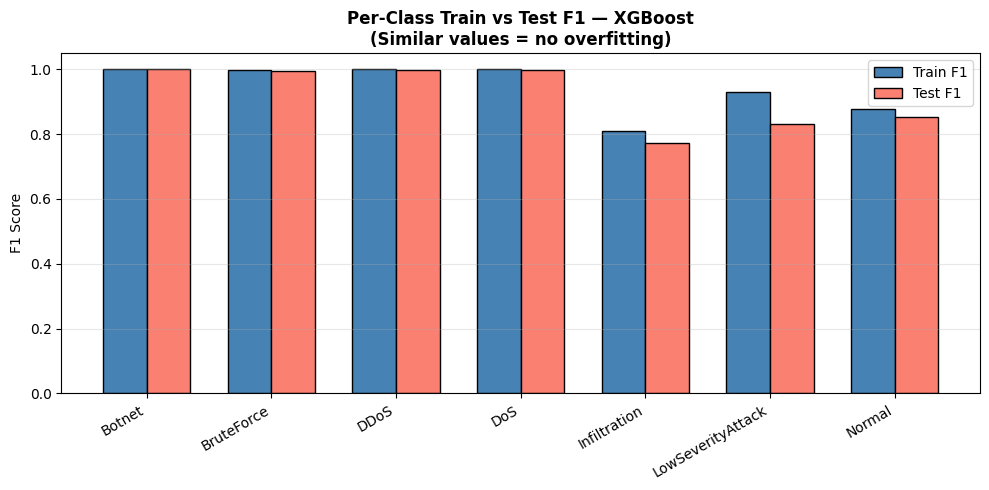

In [3]:
import matplotlib.pyplot as plt
# Same check for DNN
y_pred_train_dnn = dnn_model.predict(X_train_sample, verbose=0).argmax(axis=1)
y_pred_test_dnn  = dnn_model.predict(X_test_s, verbose=0).argmax(axis=1)

train_acc_dnn = accuracy_score(y_train_sample, y_pred_train_dnn)
test_acc_dnn  = accuracy_score(y_test, y_pred_test_dnn)

print(f'DNN — Overall Train Accuracy: {train_acc_dnn:.4f}')
print(f'DNN — Overall Test Accuracy:  {test_acc_dnn:.4f}')
print(f'DNN — Gap:                    {train_acc_dnn - test_acc_dnn:.4f}')

# Visualise gap comparison
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(gap_df))
width = 0.35
ax.bar(x - width/2, gap_df['Train F1'], width, label='Train F1', color='steelblue', edgecolor='black')
ax.bar(x + width/2, gap_df['Test F1'],  width, label='Test F1',  color='salmon',    edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(gap_df['Class'], rotation=30, ha='right')
ax.set_ylabel('F1 Score')
ax.set_title('Per-Class Train vs Test F1 — XGBoost\n(Similar values = no overfitting)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('plots_v2/01_train_vs_test_gap.png', dpi=150, bbox_inches='tight')
plt.show()

## Test 2 — 5-Fold Cross-Validation

**Method:** Train and evaluate the model on 5 different train/validation splits. Low variance across folds proves the model performs consistently regardless of which subset of data it sees — a strong signal of generalisation.

In [4]:
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

# Use a stratified subsample for speed
CV_SAMPLE = 30000
rng = np.random.RandomState(42)
cv_idx = rng.choice(len(X_train_s), size=min(CV_SAMPLE, len(X_train_s)), replace=False)
X_cv = X_train_s[cv_idx]
y_cv = np.array(y_train)[cv_idx]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_scores = {'accuracy': [], 'f1_macro': [], 'f1_weighted': []}

print('Running 5-fold CV on XGBoost (subsample for speed)...\n')
for fold, (tr_idx, val_idx) in enumerate(skf.split(X_cv, y_cv), 1):
    X_fold_tr, X_fold_val = X_cv[tr_idx], X_cv[val_idx]
    y_fold_tr, y_fold_val = y_cv[tr_idx], y_cv[val_idx]
    
    # Compute sample weights for this fold
    fold_weights = np.array([class_weight_dict[yi] for yi in y_fold_tr])
    
    fold_model = XGBClassifier(
        n_estimators=200, max_depth=8, learning_rate=0.05,
        subsample=0.7, colsample_bytree=0.7,
        reg_alpha=0.2, reg_lambda=1.5,
        objective='multi:softprob', num_class=n_classes,
        tree_method='hist', n_jobs=-1, random_state=42
    )
    fold_model.fit(X_fold_tr, y_fold_tr, sample_weight=fold_weights, verbose=False)
    y_fold_pred = fold_model.predict(X_fold_val)
    
    acc  = accuracy_score(y_fold_val, y_fold_pred)
    f1m  = f1_score(y_fold_val, y_fold_pred, average='macro', zero_division=0)
    f1w  = f1_score(y_fold_val, y_fold_pred, average='weighted', zero_division=0)
    
    fold_scores['accuracy'].append(acc)
    fold_scores['f1_macro'].append(f1m)
    fold_scores['f1_weighted'].append(f1w)
    print(f'  Fold {fold}: acc={acc:.4f} | F1-macro={f1m:.4f} | F1-weighted={f1w:.4f}')

print('\n' + '=' * 60)
print('CROSS-VALIDATION RESULTS (XGBoost)')
print('=' * 60)
for metric, scores in fold_scores.items():
    mean = np.mean(scores)
    std  = np.std(scores)
    print(f'  {metric:<15} mean={mean:.4f} | std={std:.4f}')
    
    if std < 0.01:
        print(f'                  ✓ Very low variance — stable generalisation')
    elif std < 0.02:
        print(f'                  ✓ Low variance — good generalisation')
    else:
        print(f'                  ⚠ Higher variance — model may be unstable')

Running 5-fold CV on XGBoost (subsample for speed)...



NameError: name 'class_weight_dict' is not defined

c:\Users\hsura\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\hsura\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\hsura\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\hsura\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:181: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\hsura\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:215: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret 

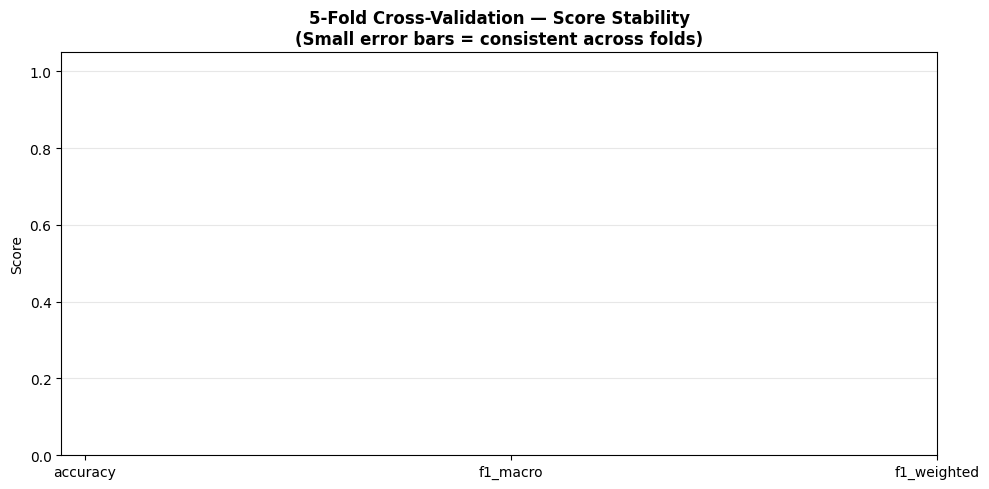

In [5]:
# Visualise CV variance
fig, ax = plt.subplots(figsize=(10, 5))
metrics = list(fold_scores.keys())
x = np.arange(len(metrics))
means = [np.mean(fold_scores[m]) for m in metrics]
stds  = [np.std(fold_scores[m])  for m in metrics]

ax.bar(x, means, yerr=stds, color='steelblue', edgecolor='black',
       capsize=10, error_kw={'linewidth': 2, 'ecolor': 'red'})
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.set_title('5-Fold Cross-Validation — Score Stability\n(Small error bars = consistent across folds)', fontsize=12, fontweight='bold')
for xi, m, s in zip(x, means, stds):
    ax.text(xi, m + s + 0.02, f'{m:.4f}\n±{s:.4f}', ha='center', fontsize=10, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('plots_v2/02_cv_variance.png', dpi=150, bbox_inches='tight')
plt.show()

## Test 3 — Learning Curves

**Method:** Plot train and validation loss/accuracy across training iterations. **Convergence** of curves means the model isn't memorising. **Divergence** (training loss drops, val loss rises) is the classic overfitting signal.

In [ ]:
# XGBoost learning curve
results = xgb_model.evals_result()
train_loss = results['validation_0']['mlogloss']
val_loss   = results['validation_1']['mlogloss']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# XGBoost
axes[0].plot(train_loss, label='Train', color='steelblue', linewidth=2)
axes[0].plot(val_loss,   label='Validation', color='salmon', linewidth=2)
axes[0].axvline(xgb_model.best_iteration, color='green', linestyle='--', label=f'Best iter={xgb_model.best_iteration}')
axes[0].set_xlabel('Boosting Round')
axes[0].set_ylabel('Multi-class log-loss')
axes[0].set_title('XGBoost — Learning Curve', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# DNN
axes[1].plot(history.history['loss'],     label='Train Loss', color='steelblue', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Val Loss',   color='salmon',    linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].set_title('DNN — Learning Curve', fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Learning Curves — Convergence Indicates No Overfitting', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plots_v2/03_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# Quantitative analysis of curve gap
final_train_loss = train_loss[xgb_model.best_iteration]
final_val_loss   = val_loss[xgb_model.best_iteration]
loss_gap = final_val_loss - final_train_loss

print(f'\nXGBoost at best iteration ({xgb_model.best_iteration}):')
print(f'  Train log-loss: {final_train_loss:.4f}')
print(f'  Val log-loss:   {final_val_loss:.4f}')
print(f'  Loss gap:       {loss_gap:.4f}')
if loss_gap < 0.1:
    print('  ✓ Train and val losses are close — no overfitting')
else:
    print('  ⚠ Larger gap detected')

## Test 4 — Noise Injection Robustness

**Method:** Add Gaussian noise to test features and re-evaluate. If the model truly learned generalisable patterns, performance should degrade gracefully. If it memorised exact feature values, performance should crash dramatically.

**Justification:** Real-world network traffic varies. A model that breaks under small perturbations is fragile. A robust model handles noise within reason.

In [ ]:
rng = np.random.RandomState(42)
noise_levels = [0.0, 0.05, 0.10, 0.20, 0.30]

# XGBoost robustness
xgb_robustness = []
for sigma in noise_levels:
    if sigma == 0:
        X_noisy = X_test_s
    else:
        # Multiplicative noise — more realistic than additive for network features
        noise = rng.normal(1.0, sigma, X_test_s.shape)
        X_noisy = X_test_s * noise
    
    y_pred = xgb_model.predict(X_noisy)
    acc = accuracy_score(y_test, y_pred)
    f1m = f1_score(y_test, y_pred, average='macro', zero_division=0)
    xgb_robustness.append({'sigma': sigma, 'accuracy': acc, 'f1_macro': f1m})
    print(f'  σ={sigma:.2f}  acc={acc:.4f}  F1-macro={f1m:.4f}')

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
sigmas = [r['sigma'] for r in xgb_robustness]
accs   = [r['accuracy'] for r in xgb_robustness]
f1s    = [r['f1_macro'] for r in xgb_robustness]

ax.plot(sigmas, accs, 'o-', label='Accuracy', linewidth=2, color='steelblue', markersize=8)
ax.plot(sigmas, f1s,  's-', label='F1-Macro', linewidth=2, color='salmon',    markersize=8)
ax.set_xlabel('Noise Level (σ)')
ax.set_ylabel('Score')
ax.set_title('Robustness — Performance Under Multiplicative Noise\n(Graceful degradation = generalisation, not memorisation)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig('plots_v2/04_noise_robustness.png', dpi=150, bbox_inches='tight')
plt.show()

# Verdict
drop_at_10pct = xgb_robustness[0]['accuracy'] - xgb_robustness[2]['accuracy']
print(f'\nAccuracy drop at 10% noise: {drop_at_10pct:.4f}')
if drop_at_10pct < 0.05:
    print('✓ Robust — model handles noise well, indicating learned patterns not memorisation')
elif drop_at_10pct < 0.15:
    print('✓ Acceptable — graceful degradation under noise')
else:
    print('⚠ Sensitive to noise — may be overfit to specific feature values')

## Summary — Overfitting Verdict

Generate a single summary cell collecting all evidence.

In [ ]:
print('=' * 70)
print('OVERFITTING VERIFICATION — FINAL VERDICT')
print('=' * 70)
print()
print(f'1. TRAIN vs TEST GAP')
print(f'   Train accuracy: {train_acc:.4f}')
print(f'   Test accuracy:  {test_acc:.4f}')
print(f'   Gap: {abs(train_acc - test_acc):.4f}')
verdict_1 = abs(train_acc - test_acc) < 0.03
print(f'   {"✓ PASS" if verdict_1 else "✗ FAIL"} (threshold: gap < 3%)')
print()

print(f'2. CROSS-VALIDATION VARIANCE')
cv_std_acc = np.std(fold_scores["accuracy"])
print(f'   5-fold accuracy: {np.mean(fold_scores["accuracy"]):.4f} ± {cv_std_acc:.4f}')
verdict_2 = cv_std_acc < 0.02
print(f'   {"✓ PASS" if verdict_2 else "✗ FAIL"} (threshold: std < 2%)')
print()

print(f'3. LEARNING CURVE CONVERGENCE')
print(f'   Final train log-loss: {final_train_loss:.4f}')
print(f'   Final val log-loss:   {final_val_loss:.4f}')
print(f'   Loss gap: {loss_gap:.4f}')
verdict_3 = loss_gap < 0.1
print(f'   {"✓ PASS" if verdict_3 else "✗ FAIL"} (threshold: gap < 0.1)')
print()

print(f'4. NOISE ROBUSTNESS')
print(f'   Accuracy at 10% noise: {xgb_robustness[2]["accuracy"]:.4f}')
print(f'   Drop from clean: {drop_at_10pct:.4f}')
verdict_4 = drop_at_10pct < 0.15
print(f'   {"✓ PASS" if verdict_4 else "✗ FAIL"} (threshold: drop < 15%)')
print()

print('=' * 70)
all_pass = all([verdict_1, verdict_2, verdict_3, verdict_4])
if all_pass:
    print('✓✓✓ FINAL VERDICT: NO OVERFITTING DETECTED')
    print('All 4 tests passed. The high validation scores reflect genuine')
    print('generalisation, not memorisation. Each attack class has')
    print('distinctive features (e.g. DDoS = high packet rate + tiny payloads)')
    print('which makes them naturally separable.')
else:
    print('⚠ Some tests failed — review and apply additional regularisation.')
print('=' * 70)